# Meeting 1 — Real spatial cell network vs. Erdős–Rényi random graphs

This notebook performs the **Meeting 1 lab exercise** on the fixed WT4 spatial cell network.

## Tasks

1. Compute the degree distribution of the real network.
2. Compute clustering.
3. Compute mean shortest-path length.
4. Generate Erdős–Rényi random graphs with matching network size and mean degree.
5. Compare the real network with the random-network baseline.
6. Compare the giant-component size with the Newman N11 prediction.

## Fixed real network

- Dataset: `GSE309522`
- Sample: `WT4 / GSM9268674`
- Nodes: 10,000 spatially local Xenium cells
- Edge rule: two cell centroids are connected when their Euclidean distance is at most `r = 15`


In [1]:
import os
from pathlib import Path
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.optimize import brentq
from scipy.stats import poisson


def find_repo_root(start: Path = Path.cwd()) -> Path:
    """Find the Git repository root from the current working directory."""
    start = start.resolve()
    for path in [start, *start.parents]:
        if (path / ".git").exists():
            return path
    raise RuntimeError("Could not find the Git repository root.")


ROOT = find_repo_root()

DATA_ROOT = Path(
    os.environ.get(
        "NT_ABM_DATA_DIR",
        ROOT / "data"
    )
).resolve()
GRAPH_PATH = DATA_ROOT / "processed" / "WT4_spatial_network_r15.graphml"
RESULTS_DIR = ROOT / "results" / "meeting_1"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not GRAPH_PATH.exists():
    raise FileNotFoundError(f"Missing graph file: {GRAPH_PATH}")

print("Project root:", ROOT)
print("Graph:", GRAPH_PATH)
print("Results:", RESULTS_DIR)


Project root: E:\Network_Theory_Class\NT_and_ABM
Graph: E:\Network_Theory_Class\NT_and_ABM_data\processed\WT4_spatial_network_r15.graphml
Results: E:\Network_Theory_Class\NT_and_ABM\results\meeting_1


## 1. Load and verify the real network

In [2]:
G = nx.read_graphml(GRAPH_PATH)

n = G.number_of_nodes()
m = G.number_of_edges()
mean_degree = 2 * m / n

n_components = nx.number_connected_components(G)
n_isolates = nx.number_of_isolates(G)

largest_nodes = max(nx.connected_components(G), key=len)
G_lcc = G.subgraph(largest_nodes).copy()

lcc_size = G_lcc.number_of_nodes()
lcc_fraction = lcc_size / n

real_basic = pd.Series({
    "nodes": n,
    "edges": m,
    "mean_degree": mean_degree,
    "isolates": n_isolates,
    "components": n_components,
    "largest_component_size": lcc_size,
    "largest_component_fraction": lcc_fraction,
})

display(real_basic.to_frame("value"))

assert n == 10_000
assert m == 50_583


,value
nodes,10000.0000
edges,50583.0000
mean_degree,10.1166
isolates,26.0000
components,41.0000
largest_component_size,8689.0000
largest_component_fraction,0.8689


## 2. Degree distribution

For an undirected graph, the degree \(k_i\) of node \(i\) is the number of adjacent nodes.

The empirical degree distribution is

\[
P(k)=\frac{N_k}{n},
\]

where \(N_k\) is the number of nodes with degree \(k\).


In [3]:
degrees = np.fromiter((d for _, d in G.degree()), dtype=int)

degree_counts = (
    pd.Series(degrees)
    .value_counts()
    .sort_index()
    .rename_axis("degree")
    .reset_index(name="count")
)

degree_counts["probability"] = degree_counts["count"] / n

display(degree_counts.head(15))

print("Minimum degree:", degrees.min())
print("Median degree:", np.median(degrees))
print("Mean degree:", degrees.mean())
print("Maximum degree:", degrees.max())


,degree,count,probability
0,0,26,0.0026
1,1,22,0.0022
2,2,54,0.0054
3,3,90,0.0090
4,4,151,0.0151
5,5,328,0.0328
6,6,518,0.0518
7,7,705,0.0705
8,8,964,0.0964
9,9,1221,0.1221


Minimum degree: 0
Median degree: 10.0
Mean degree: 10.1166
Maximum degree: 23


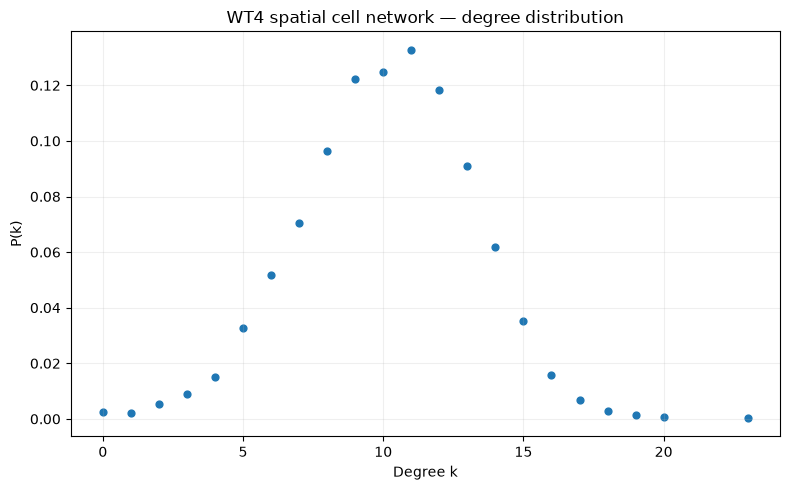

Saved: E:\Network_Theory_Class\NT_and_ABM\results\meeting_1\real_degree_distribution.png


In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(
    degree_counts["degree"],
    degree_counts["probability"],
    s=24,
)

plt.xlabel("Degree k")
plt.ylabel("P(k)")
plt.title("WT4 spatial cell network — degree distribution")
plt.grid(alpha=0.2)
plt.tight_layout()

degree_plot_path = RESULTS_DIR / "real_degree_distribution.png"
plt.savefig(degree_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", degree_plot_path)


## 3. Clustering

Two related clustering quantities are reported:

- **Average local clustering coefficient**: mean of the node-level clustering coefficients.
- **Transitivity**: three times the number of triangles divided by the number of connected triples.

Both are useful because spatial networks often contain many local triangles.


In [5]:
t0 = time.perf_counter()

real_average_clustering = nx.average_clustering(G)
real_transitivity = nx.transitivity(G)

elapsed = time.perf_counter() - t0

print(f"Average clustering coefficient: {real_average_clustering:.6f}")
print(f"Transitivity: {real_transitivity:.6f}")
print(f"Elapsed: {elapsed:.2f} s")


Average clustering coefficient: 0.518494
Transitivity: 0.518700
Elapsed: 0.39 s


## 4. Mean shortest-path length

The real graph is disconnected, so a finite path does not exist between every pair of nodes.

Therefore, the mean shortest-path length is computed on the **largest connected component (LCC)**, and the LCC fraction is reported alongside it.

> This exact NetworkX calculation can take some time because it runs shortest-path searches from every node in the LCC.


In [6]:
t0 = time.perf_counter()

real_mean_shortest_path = nx.average_shortest_path_length(G_lcc)

elapsed = time.perf_counter() - t0

print("LCC nodes:", G_lcc.number_of_nodes())
print(f"LCC fraction: {lcc_fraction:.6f}")
print(f"Mean shortest-path length in LCC: {real_mean_shortest_path:.6f}")
print(f"Elapsed: {elapsed:.2f} s")


LCC nodes: 8689
LCC fraction: 0.868900
Mean shortest-path length in LCC: 37.976124
Elapsed: 96.21 s


## 5. Matched Erdős–Rényi graph

To match the real network **exactly in node count and edge count**, we use the Erdős–Rényi \(G(n,m)\) ensemble:

\[
n_{\mathrm{ER}}=n_{\mathrm{real}}, \qquad
m_{\mathrm{ER}}=m_{\mathrm{real}}.
\]

This also makes the mean degree identical:

\[
\langle k\rangle = \frac{2m}{n}.
\]

For large sparse graphs, \(G(n,m)\) and \(G(n,p)\) are asymptotically equivalent, with

\[
p \approx \frac{\langle k\rangle}{n-1}.
\]


In [7]:
ER_SEED = 42

G_er = nx.gnm_random_graph(n=n, m=m, seed=ER_SEED)

er_mean_degree = 2 * G_er.number_of_edges() / G_er.number_of_nodes()
er_components = nx.number_connected_components(G_er)
er_isolates = nx.number_of_isolates(G_er)

er_largest_nodes = max(nx.connected_components(G_er), key=len)
G_er_lcc = G_er.subgraph(er_largest_nodes).copy()

er_lcc_size = G_er_lcc.number_of_nodes()
er_lcc_fraction = er_lcc_size / n

print("ER nodes:", G_er.number_of_nodes())
print("ER edges:", G_er.number_of_edges())
print("ER mean degree:", er_mean_degree)
print("ER isolates:", er_isolates)
print("ER components:", er_components)
print("ER LCC size:", er_lcc_size)
print("ER LCC fraction:", er_lcc_fraction)


ER nodes: 10000
ER edges: 50583
ER mean degree: 10.1166
ER isolates: 0
ER components: 1
ER LCC size: 10000
ER LCC fraction: 1.0


### Degree distribution: real vs. ER

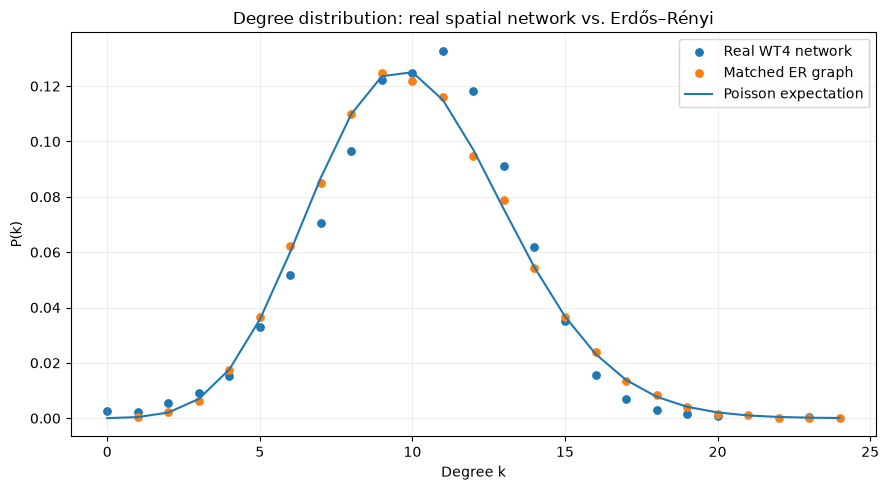

Saved: E:\Network_Theory_Class\NT_and_ABM\results\meeting_1\degree_distribution_real_vs_er.png


In [8]:
er_degrees = np.fromiter((d for _, d in G_er.degree()), dtype=int)

er_degree_counts = (
    pd.Series(er_degrees)
    .value_counts()
    .sort_index()
    .rename_axis("degree")
    .reset_index(name="count")
)
er_degree_counts["probability"] = er_degree_counts["count"] / n

k_max = max(degrees.max(), er_degrees.max())
k_values = np.arange(0, k_max + 1)
poisson_pmf = poisson.pmf(k_values, mu=mean_degree)

plt.figure(figsize=(9, 5))

plt.scatter(
    degree_counts["degree"],
    degree_counts["probability"],
    s=28,
    label="Real WT4 network",
)

plt.scatter(
    er_degree_counts["degree"],
    er_degree_counts["probability"],
    s=28,
    label="Matched ER graph",
)

plt.plot(
    k_values,
    poisson_pmf,
    linewidth=1.5,
    label="Poisson expectation",
)

plt.xlabel("Degree k")
plt.ylabel("P(k)")
plt.title("Degree distribution: real spatial network vs. Erdős–Rényi")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

comparison_degree_plot = RESULTS_DIR / "degree_distribution_real_vs_er.png"
plt.savefig(comparison_degree_plot, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", comparison_degree_plot)


### Clustering: real vs. ER

In [9]:
t0 = time.perf_counter()

er_average_clustering = nx.average_clustering(G_er)
er_transitivity = nx.transitivity(G_er)

elapsed = time.perf_counter() - t0

p_equivalent = mean_degree / (n - 1)

print(f"Real average clustering: {real_average_clustering:.6f}")
print(f"ER average clustering:   {er_average_clustering:.6f}")
print(f"ER theoretical C ≈ p:    {p_equivalent:.6f}")
print()
print(f"Real transitivity: {real_transitivity:.6f}")
print(f"ER transitivity:   {er_transitivity:.6f}")
print(f"Elapsed: {elapsed:.2f} s")


Real average clustering: 0.518494
ER average clustering:   0.001132
ER theoretical C ≈ p:    0.001012

Real transitivity: 0.518700
ER transitivity:   0.001074
Elapsed: 0.35 s


### Mean shortest-path length: real vs. ER

In [10]:
t0 = time.perf_counter()

er_mean_shortest_path = nx.average_shortest_path_length(G_er_lcc)

elapsed = time.perf_counter() - t0

print(f"Real LCC fraction: {lcc_fraction:.6f}")
print(f"ER LCC fraction:   {er_lcc_fraction:.6f}")
print()
print(f"Real mean shortest path (LCC): {real_mean_shortest_path:.6f}")
print(f"ER mean shortest path (LCC):   {er_mean_shortest_path:.6f}")
print(f"Elapsed: {elapsed:.2f} s")


Real LCC fraction: 0.868900
ER LCC fraction:   1.000000

Real mean shortest path (LCC): 37.976124
ER mean shortest path (LCC):   4.241269
Elapsed: 78.49 s


## 6. Giant component across multiple ER realizations

A single random graph is only one realization of the ensemble. To assess the typical giant-component size, generate multiple matched \(G(n,m)\) networks.

This loop computes only inexpensive component-level quantities; it does **not** repeat the exact all-pairs shortest-path calculation.


In [11]:
N_ER_REPLICATES = 50

er_rep_results = []

t0 = time.perf_counter()

for seed in range(N_ER_REPLICATES):
    H = nx.gnm_random_graph(n=n, m=m, seed=seed)

    largest = max(nx.connected_components(H), key=len)

    er_rep_results.append({
        "seed": seed,
        "edges": H.number_of_edges(),
        "mean_degree": 2 * H.number_of_edges() / n,
        "components": nx.number_connected_components(H),
        "isolates": nx.number_of_isolates(H),
        "giant_component_size": len(largest),
        "giant_component_fraction": len(largest) / n,
    })

er_replicates = pd.DataFrame(er_rep_results)

elapsed = time.perf_counter() - t0

display(er_replicates.head())
display(er_replicates.describe())

print(f"Elapsed for {N_ER_REPLICATES} ER realizations: {elapsed:.2f} s")


,seed,edges,mean_degree,components,isolates,giant_component_size,giant_component_fraction
0,0,50583,10.1166,1,0,10000,1.0000
1,1,50583,10.1166,3,2,9998,0.9998
2,2,50583,10.1166,1,0,10000,1.0000
3,3,50583,10.1166,2,1,9999,0.9999
4,4,50583,10.1166,1,0,10000,1.0000


,seed,edges,mean_degree,components,isolates,giant_component_size,giant_component_fraction
count,50.00000,50.0,50.0000,50.000000,50.000000,50.000000,50.000000
mean,24.50000,50583.0,10.1166,1.420000,0.420000,9999.580000,0.999958
std,14.57738,0.0,0.0000,0.784805,0.784805,0.784805,0.000078
min,0.00000,50583.0,10.1166,1.000000,0.000000,9996.000000,0.999600
25%,12.25000,50583.0,10.1166,1.000000,0.000000,9999.000000,0.999900
50%,24.50000,50583.0,10.1166,1.000000,0.000000,10000.000000,1.000000
75%,36.75000,50583.0,10.1166,2.000000,1.000000,10000.000000,1.000000
max,49.00000,50583.0,10.1166,5.000000,4.000000,10000.000000,1.000000


Elapsed for 50 ER realizations: 14.39 s


## 7. Newman N11 giant-component prediction

For an Erdős–Rényi/Poisson random graph with mean degree \(c\), the giant-component fraction \(S\) satisfies

\[
S = 1-e^{-cS}.
\]

For \(c>1\), this equation has a positive giant-component solution in addition to the trivial \(S=0\) solution.


In [12]:
c = mean_degree

def giant_component_equation(S, c):
    return S - (1 - np.exp(-c * S))

if c <= 1:
    S_theory = 0.0
else:
    S_theory = brentq(
        lambda S: giant_component_equation(S, c),
        1e-12,
        1 - 1e-12,
    )

er_gc_mean = er_replicates["giant_component_fraction"].mean()
er_gc_std = er_replicates["giant_component_fraction"].std(ddof=1)

print(f"Mean degree c: {c:.6f}")
print(f"N11 theoretical giant-component fraction: {S_theory:.6f}")
print(f"ER simulated mean giant-component fraction: {er_gc_mean:.6f}")
print(f"ER simulated SD: {er_gc_std:.6f}")
print(f"Real spatial-network giant-component fraction: {lcc_fraction:.6f}")


Mean degree c: 10.116600
N11 theoretical giant-component fraction: 0.999960
ER simulated mean giant-component fraction: 0.999958
ER simulated SD: 0.000078
Real spatial-network giant-component fraction: 0.868900


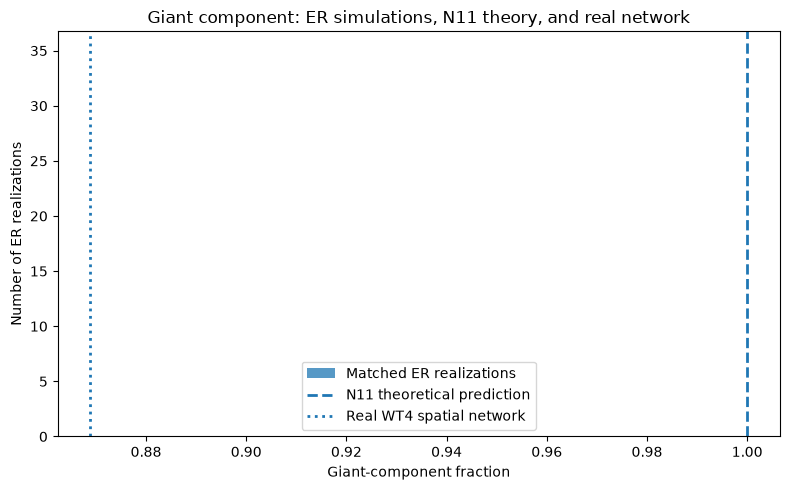

Saved: E:\Network_Theory_Class\NT_and_ABM\results\meeting_1\giant_component_real_er_theory.png


In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    er_replicates["giant_component_fraction"],
    bins=12,
    alpha=0.75,
    label="Matched ER realizations",
)

plt.axvline(
    S_theory,
    linestyle="--",
    linewidth=2,
    label="N11 theoretical prediction",
)

plt.axvline(
    lcc_fraction,
    linestyle=":",
    linewidth=2,
    label="Real WT4 spatial network",
)

plt.xlabel("Giant-component fraction")
plt.ylabel("Number of ER realizations")
plt.title("Giant component: ER simulations, N11 theory, and real network")
plt.legend()
plt.tight_layout()

gc_plot_path = RESULTS_DIR / "giant_component_real_er_theory.png"
plt.savefig(gc_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", gc_plot_path)


## 8. Final comparison table

In [14]:
comparison = pd.DataFrame({
    "metric": [
        "nodes",
        "edges",
        "mean_degree",
        "average_clustering",
        "transitivity",
        "LCC_fraction",
        "mean_shortest_path_LCC",
    ],
    "real_WT4": [
        n,
        m,
        mean_degree,
        real_average_clustering,
        real_transitivity,
        lcc_fraction,
        real_mean_shortest_path,
    ],
    "matched_ER_seed42": [
        G_er.number_of_nodes(),
        G_er.number_of_edges(),
        er_mean_degree,
        er_average_clustering,
        er_transitivity,
        er_lcc_fraction,
        er_mean_shortest_path,
    ],
})

display(comparison)

comparison_path = RESULTS_DIR / "real_vs_er_comparison.csv"
er_replicates_path = RESULTS_DIR / "er_giant_component_replicates.csv"

comparison.to_csv(comparison_path, index=False)
er_replicates.to_csv(er_replicates_path, index=False)

print("Saved:", comparison_path)
print("Saved:", er_replicates_path)


,metric,real_WT4,matched_ER_seed42
0,nodes,10000.000000,10000.000000
1,edges,50583.000000,50583.000000
2,mean_degree,10.116600,10.116600
3,average_clustering,0.518494,0.001132
4,transitivity,0.518700,0.001074
5,LCC_fraction,0.868900,1.000000
6,mean_shortest_path_LCC,37.976124,4.241269


Saved: E:\Network_Theory_Class\NT_and_ABM\results\meeting_1\real_vs_er_comparison.csv
Saved: E:\Network_Theory_Class\NT_and_ABM\results\meeting_1\er_giant_component_replicates.csv


## 9. Report-ready interpretation

Use the calculated values above to support the following interpretation:

- The real spatial cell network and the ER baseline have the same \(n\), \(m\), and mean degree by construction.
- Any differences in degree distribution, clustering, path length, or component structure therefore reflect **network organization beyond network size and mean degree**.
- The N11 equation is a prediction for the Erdős–Rényi/Poisson random-graph model, not a universal formula for arbitrary spatial networks.
- A substantial difference between the real-network giant component and the N11/ER result is therefore evidence that spatial organization, local geometry, and fragmentation matter.
- Mean shortest-path length is reported on the LCC because the real network is disconnected.

### Methodological caveat

The master graph is a spatial ROI extracted from a larger tissue section. Cells near the ROI boundary may have biological neighbors outside the selected region, which can affect degree and component structure near the boundary.
